# 06 · Comparación y selección del modelo
Lee los resultados guardados por los notebooks 01–05.

In [1]:
# Librerías base
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings("ignore")

# Funciones compartidas del proyecto (métricas, gráficas, rutas) -> archivo churn_utils.py
from churn_utils import *

pd.options.display.max_columns = None
plt.rcParams["figure.dpi"] = 100

import seaborn as sns
import joblib
from sklearn.metrics import roc_curve, roc_auc_score, precision_recall_curve
from sklearn.ensemble import GradientBoostingClassifier, HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.inspection import PartialDependenceDisplay

In [2]:
# Cargar los datos ya preparados por el notebook 00 (mismo train/test para TODOS los modelos)
datos = cargar_datos_modelo()
X_train, X_test = datos["X_train"], datos["X_test"]
y_train, y_test = datos["y_train"], datos["y_test"]

print("Entrenamiento:", X_train.shape, "| Test:", X_test.shape)
print("Tasa de fuga en train: %.2f%% | en test: %.2f%%" % (100 * y_train.mean(), 100 * y_test.mean()))

Entrenamiento: (8101, 33) | Test: (2026, 33)
Tasa de fuga en train: 16.07% | en test: 16.04%


## 1. Tabla comparativa (umbral 0,5)

In [3]:
resultados = cargar_resultados()
print("Modelos encontrados:", list(resultados.keys()))

familia = {"Regresión Logística (Gradiente)": "Gradiente", "SVM RBF": "SVM", "SVM Polinomial": "SVM", "SVR score": "SVM",
           "Gradient Boosting": "Gradient Boosting", "HistGradientBoosting": "Gradient Boosting",
           "Red Neuronal Keras": "Red neuronal", "MLP sklearn": "Red neuronal",
           "Random Forest": "Ensamble", "Bagging (árboles)": "Ensamble", "Extra Trees": "Ensamble",
           "AdaBoost": "Ensamble", "Voting": "Ensamble", "Stacking": "Ensamble"}

tabla = pd.DataFrame([r["metricas"] for r in resultados.values()])
tabla["Modelo"] = list(resultados.keys())
tabla.insert(1, "Familia", tabla["Modelo"].map(familia))
tabla = tabla.drop(columns="Umbral").sort_values("AUC", ascending=False).reset_index(drop=True)
tabla.to_excel(f"{RESULTADOS_DIR}/tabla_comparativa_modelos.xlsx", index=False)
tabla.style.format({c: "{:.4f}" for c in tabla.columns if c not in ("Modelo", "Familia")}).background_gradient(
    subset=["AUC", "PR-AUC", "F1", "Sensibilidad"], cmap="Greens")

Modelos encontrados: ['AdaBoost', 'Bagging (árboles)', 'Extra Trees', 'Gradient Boosting', 'HistGradientBoosting', 'MLP sklearn', 'Random Forest', 'Red Neuronal Keras', 'Regresión Logística (Gradiente)', 'SVM Polinomial', 'SVM RBF', 'SVR score', 'Stacking', 'Voting']


,Modelo,Familia,AUC,PR-AUC,Accuracy,Sensibilidad,Especificidad,Precision (VPP),VPN,F1
0,HistGradientBoosting,Gradient Boosting,0.9947,0.9744,0.9704,0.9477,0.9747,0.8775,0.9899,0.9112
1,Gradient Boosting,Gradient Boosting,0.9945,0.9747,0.9729,0.9108,0.9847,0.9193,0.9830,0.9150
2,Stacking,Ensamble,0.9941,0.9720,0.9724,0.8923,0.9877,0.9325,0.9796,0.9119
3,AdaBoost,Ensamble,0.9919,0.9624,0.9630,0.8615,0.9824,0.9032,0.9738,0.8819
4,Random Forest,Ensamble,0.9910,0.9573,0.9590,0.7815,0.9929,0.9549,0.9597,0.8596
5,Bagging (árboles),Ensamble,0.9900,0.9544,0.9674,0.8985,0.9806,0.8985,0.9806,0.8985
6,Extra Trees,Ensamble,0.9874,0.9476,0.9580,0.8154,0.9853,0.9138,0.9654,0.8618
7,Voting,Ensamble,0.9871,0.9443,0.9566,0.7877,0.9888,0.9309,0.9606,0.8533
8,Red Neuronal Keras,Red neuronal,0.9653,0.8569,0.9269,0.7169,0.9671,0.8062,0.9470,0.7590
9,SVM RBF,SVM,0.9543,0.8302,0.9269,0.6708,0.9759,0.8417,0.9394,0.7466


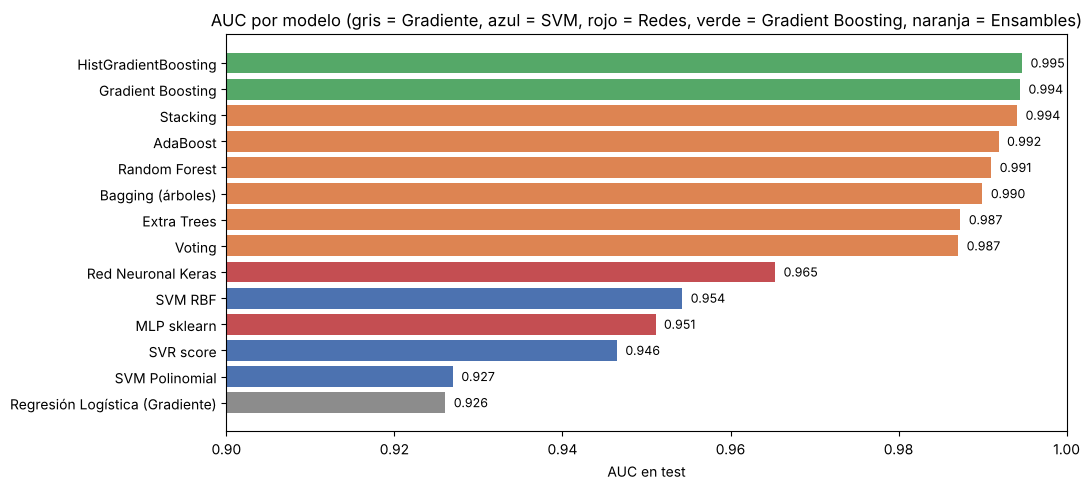

In [4]:
fig, ax = plt.subplots(figsize=(11, 5))
t = tabla.sort_values("AUC")
ax.barh(t["Modelo"], t["AUC"], color=t["Familia"].map({"Gradiente": "#8C8C8C", "SVM": "#4C72B0", "Gradient Boosting": "#55A868",
                                                         "Red neuronal": "#C44E52", "Ensamble": "#DD8452"}))
for i, v in enumerate(t["AUC"]):
    ax.text(v + 0.001, i, f"{v:.3f}", va="center", fontsize=9)
ax.set_xlim(0.90, 1.0); ax.set_xlabel("AUC en test")
ax.set_title("AUC por modelo (gris = Gradiente, azul = SVM, rojo = Redes, verde = Gradient Boosting, naranja = Ensambles)")
plt.tight_layout(); plt.savefig(f"{FIGURAS_DIR}/comparacion_auc.png", bbox_inches="tight"); plt.show()

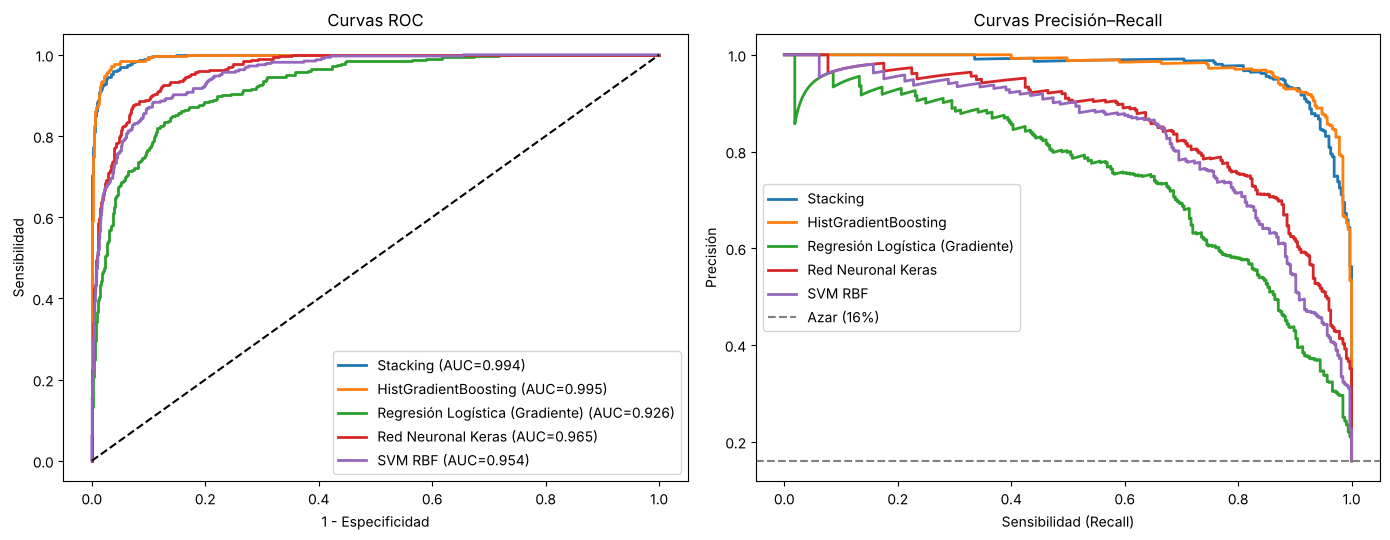

In [5]:
# Curvas ROC y Precisión-Recall del mejor modelo de cada familia
mejor_por_familia = tabla.groupby("Familia").first()["Modelo"].tolist()
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
for nombre in mejor_por_familia:
    r = resultados[nombre]
    fpr, tpr, _ = roc_curve(r["y_test"], r["y_prob"])
    axes[0].plot(fpr, tpr, lw=2, label=f"{nombre} (AUC={roc_auc_score(r['y_test'], r['y_prob']):.3f})")
    p, rc, _ = precision_recall_curve(r["y_test"], r["y_prob"])
    axes[1].plot(rc, p, lw=2, label=nombre)
axes[0].plot([0, 1], [0, 1], "k--"); axes[0].set_xlabel("1 - Especificidad"); axes[0].set_ylabel("Sensibilidad")
axes[0].set_title("Curvas ROC"); axes[0].legend(loc="lower right")
axes[1].axhline(y_test.mean(), color="gray", ls="--", label="Azar (16%)")
axes[1].set_xlabel("Sensibilidad (Recall)"); axes[1].set_ylabel("Precisión"); axes[1].set_title("Curvas Precisión–Recall"); axes[1].legend()
plt.tight_layout(); plt.savefig(f"{FIGURAS_DIR}/comparacion_roc_pr.png", bbox_inches="tight"); plt.show()

* La curva precisión–recall es más exigente con clases desbalanceadas.

## 2. Intervalos de confianza por bootstrap

In [6]:
rng = np.random.default_rng(SEMILLA)
top = tabla["Modelo"].head(6).tolist()
yt = resultados[top[0]]["y_test"]
boot = {m: [] for m in top}
for _ in range(1000):
    idx = rng.integers(0, len(yt), len(yt))
    if yt[idx].sum() == 0:
        continue
    for m in top:
        boot[m].append(roc_auc_score(yt[idx], resultados[m]["y_prob"][idx]))
ic = pd.DataFrame({m: {"AUC": roc_auc_score(yt, resultados[m]["y_prob"]),
                       "IC 95% inf": np.percentile(v, 2.5), "IC 95% sup": np.percentile(v, 97.5)} for m, v in boot.items()}).T
mejor = top[0]
ic["% veces que el mejor le gana"] = [np.mean(np.array(boot[mejor]) >= np.array(boot[m])) for m in top]
ic.round(4)

,AUC,IC 95% inf,IC 95% sup,% veces que el mejor le gana
HistGradientBoosting,0.9947,0.9923,0.9968,1.000
Gradient Boosting,0.9945,0.9920,0.9967,0.637
Stacking,0.9941,0.9918,0.9965,0.859
AdaBoost,0.9919,0.9891,0.9947,1.000
Random Forest,0.9910,0.9877,0.9941,1.000
Bagging (árboles),0.9900,0.9859,0.9937,1.000


## 3. Modelo elegido

In [7]:
# Modelo elegido (puede cambiarse por cualquier nombre de la tabla)
MODELO_ELEGIDO = "Gradient Boosting"
r_final = resultados[MODELO_ELEGIDO]
y_prob_final = r_final["y_prob"]
print("Modelo elegido:", MODELO_ELEGIDO)
print("Hiperparámetros:", r_final["mejores_parametros"])
tabla[tabla["Modelo"] == MODELO_ELEGIDO].round(4)

Modelo elegido: Gradient Boosting
Hiperparámetros: {'learning_rate': 0.1, 'max_depth': 3, 'n_estimators': 400, 'subsample': 1.0}


,Modelo,Familia,AUC,PR-AUC,Accuracy,Sensibilidad,Especificidad,Precision (VPP),VPN,F1
1,Gradient Boosting,Gradient Boosting,0.9945,0.9747,0.9729,0.9108,0.9847,0.9193,0.983,0.915


## 4. Umbral de decisión

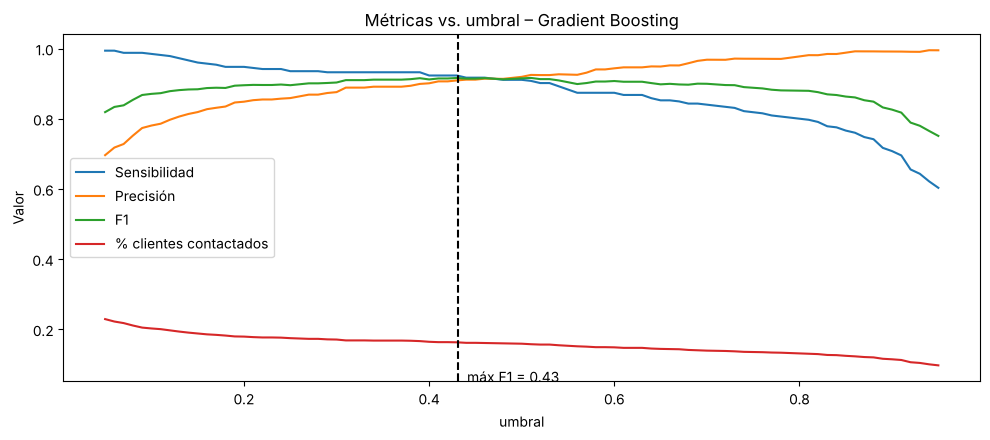

Umbral que maximiza F1: 0.431 (F1 = 0.9174)


In [8]:
umbrales = np.linspace(0.05, 0.95, 91)
curva = pd.DataFrame([{"umbral": u,
                       "Sensibilidad": custom_sensitivity_score(y_test, (y_prob_final > u).astype(int)),
                       "Precisión": custom_ppv_score(y_test, (y_prob_final > u).astype(int)),
                       "Especificidad": custom_specificity_score(y_test, (y_prob_final > u).astype(int)),
                       "% clientes contactados": (y_prob_final > u).mean()} for u in umbrales])
curva["F1"] = 2 * curva["Sensibilidad"] * curva["Precisión"] / (curva["Sensibilidad"] + curva["Precisión"] + 1e-12)

u_f1, f1_max = umbral_optimo_f1(y_test, y_prob_final)
ax = curva.plot(x="umbral", y=["Sensibilidad", "Precisión", "F1", "% clientes contactados"], figsize=(10, 4.5))
ax.axvline(u_f1, color="k", ls="--"); ax.text(u_f1 + 0.01, 0.05, f"máx F1 = {u_f1:.2f}")
ax.set_title(f"Métricas vs. umbral – {MODELO_ELEGIDO}"); ax.set_ylabel("Valor")
plt.tight_layout(); plt.savefig(f"{FIGURAS_DIR}/umbral_metricas.png", bbox_inches="tight"); plt.show()
print(f"Umbral que maximiza F1: {u_f1:.3f} (F1 = {f1_max:.4f})")

### 4.1 Umbral de negocio
**Supuestos ilustrativos** (reemplazar por cifras del banco): margen por cliente, costo del beneficio y tasa de éxito.

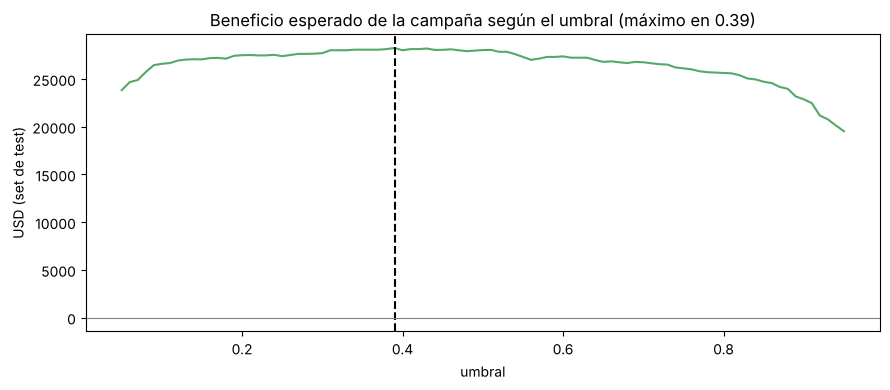

Umbral de negocio: 0.39
Beneficio con 'contactar a todos': -69560.0


,umbral,Sensibilidad,Precisión,Especificidad,% clientes contactados,F1,"Beneficio (USD, test)"
34,0.39,0.932,0.899,0.980,0.166,0.915,28260.0
38,0.43,0.923,0.909,0.982,0.163,0.916,28200.0
45,0.50,0.911,0.919,0.985,0.159,0.915,28040.0


In [9]:
VALOR_CLIENTE = 400      # USD / año (supuesto)
COSTO_BENEFICIO = 60     # USD por cliente contactado (supuesto)
TASA_EXITO = 0.40        # 40% de los clientes en riesgo contactados se retienen (supuesto)

def beneficio(y_true, y_prob, u):
    pred = (y_prob > u).astype(int)
    tp = ((pred == 1) & (np.asarray(y_true) == 1)).sum()
    contactados = pred.sum()
    return tp * TASA_EXITO * VALOR_CLIENTE - contactados * COSTO_BENEFICIO

curva["Beneficio (USD, test)"] = [beneficio(y_test, y_prob_final, u) for u in umbrales]
u_negocio = curva.loc[curva["Beneficio (USD, test)"].idxmax(), "umbral"]

ax = curva.plot(x="umbral", y="Beneficio (USD, test)", figsize=(9, 4), legend=False, color="#55A868")
ax.axvline(u_negocio, color="k", ls="--"); ax.axhline(0, color="gray", lw=0.8)
ax.set_title(f"Beneficio esperado de la campaña según el umbral (máximo en {u_negocio:.2f})"); ax.set_ylabel("USD (set de test)")
plt.tight_layout(); plt.savefig(f"{FIGURAS_DIR}/umbral_beneficio.png", bbox_inches="tight"); plt.show()

comp_umbral = curva[curva["umbral"].round(2).isin([0.5, round(u_f1, 2), round(u_negocio, 2)])]
print(f"Umbral de negocio: {u_negocio:.2f}")
print("Beneficio con 'contactar a todos':", beneficio(y_test, y_prob_final, -1))
comp_umbral.round(3)

Métricas del modelo: Gradient Boosting - umbral negocio  (umbral = 0.39)

Matriz de confusión (formato clase: filas = predicho, columnas = real):
[[1667   22]
 [  34  303]]
 Accuracy        : 0.9724
 Sensibilidad    : 0.9323
 Especificidad   : 0.9800
 Precision (VPP) : 0.8991
 VPN             : 0.9870
 F1              : 0.9154
 AUC             : 0.9945
 PR-AUC          : 0.9747


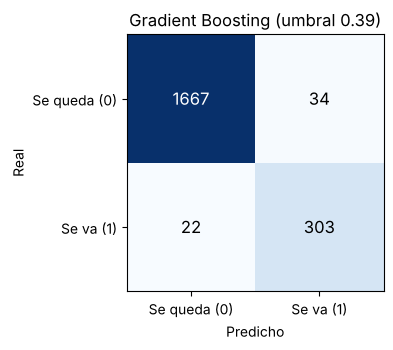

In [10]:
# Métricas finales con el umbral de negocio
UMBRAL_FINAL = float(round(u_negocio, 2))
metricas_finales = evaluar_modelo(f"{MODELO_ELEGIDO} - umbral negocio", y_test, y_prob_final, class_threshold=UMBRAL_FINAL, graficar=False)
plot_confusion(y_test, (y_prob_final > UMBRAL_FINAL).astype(int), f"{MODELO_ELEGIDO} (umbral {UMBRAL_FINAL})")

## 5. Ganancia y lift

In [11]:
gan = tabla_ganancia(y_test, y_prob_final)
gan.round(3)

,clientes,fugas,prob_min,prob_max,tasa_fuga,%_clientes_acum,%_fugas_capturadas_acum,lift,lift_acum
decil,,,,,,,,,
1,203,202,0.941,1.000,0.995,0.1,0.622,6.203,6.203
2,203,117,0.111,0.939,0.576,0.2,0.982,3.593,4.898
3,202,4,0.013,0.105,0.020,0.3,0.994,0.123,3.312
4,203,2,0.004,0.012,0.010,0.4,1.000,0.061,2.498
5,202,0,0.002,0.004,0.000,0.5,1.000,0.000,2.000
6,203,0,0.001,0.002,0.000,0.6,1.000,0.000,1.666
7,202,0,0.001,0.001,0.000,0.7,1.000,0.000,1.429
8,203,0,0.001,0.001,0.000,0.8,1.000,0.000,1.250
9,202,0,0.000,0.001,0.000,0.9,1.000,0.000,1.111


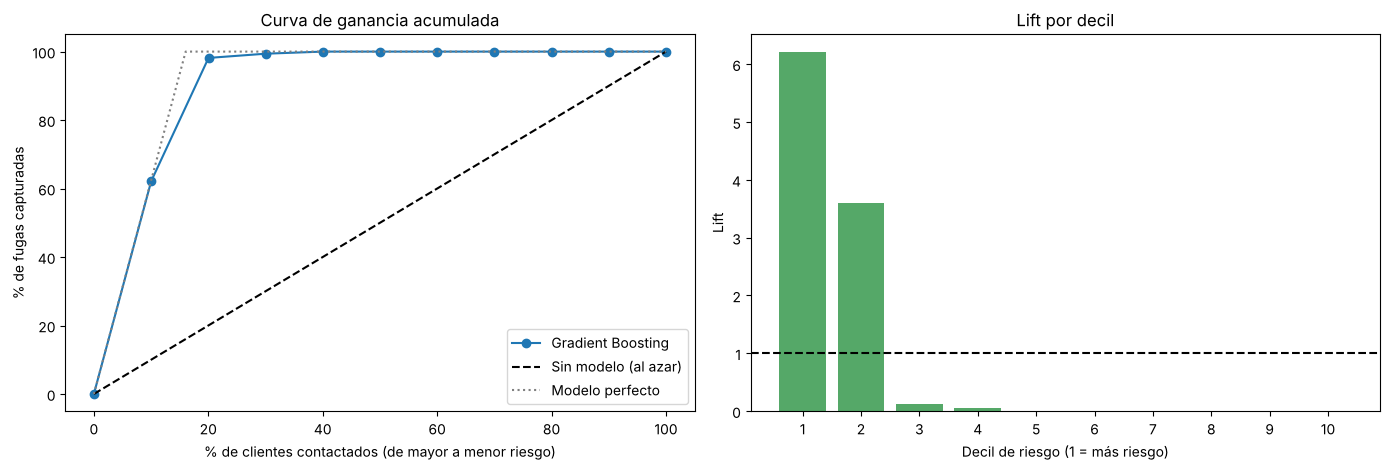

Contactando al 10% de mayor riesgo se captura el 62.2% de las fugas (lift 6.2x)
Contactando al 20% de mayor riesgo se captura el 98.2% de las fugas


In [12]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
x = np.r_[0, gan["%_clientes_acum"].values] * 100
axes[0].plot(x, np.r_[0, gan["%_fugas_capturadas_acum"].values] * 100, marker="o", label=MODELO_ELEGIDO)
axes[0].plot([0, 100], [0, 100], "k--", label="Sin modelo (al azar)")
axes[0].plot([0, y_test.mean() * 100, 100], [0, 100, 100], ":", color="gray", label="Modelo perfecto")
axes[0].set_xlabel("% de clientes contactados (de mayor a menor riesgo)"); axes[0].set_ylabel("% de fugas capturadas")
axes[0].set_title("Curva de ganancia acumulada"); axes[0].legend()
axes[1].bar(gan.index.astype(str), gan["lift"], color="#55A868"); axes[1].axhline(1, color="k", ls="--")
axes[1].set_xlabel("Decil de riesgo (1 = más riesgo)"); axes[1].set_ylabel("Lift"); axes[1].set_title("Lift por decil")
plt.tight_layout(); plt.savefig(f"{FIGURAS_DIR}/ganancia_lift.png", bbox_inches="tight"); plt.show()
print(f"Contactando al 10% de mayor riesgo se captura el {gan['%_fugas_capturadas_acum'].iloc[0]:.1%} de las fugas (lift {gan['lift'].iloc[0]:.1f}x)")
print(f"Contactando al 20% de mayor riesgo se captura el {gan['%_fugas_capturadas_acum'].iloc[1]:.1%} de las fugas")

## 6. Dependencia parcial

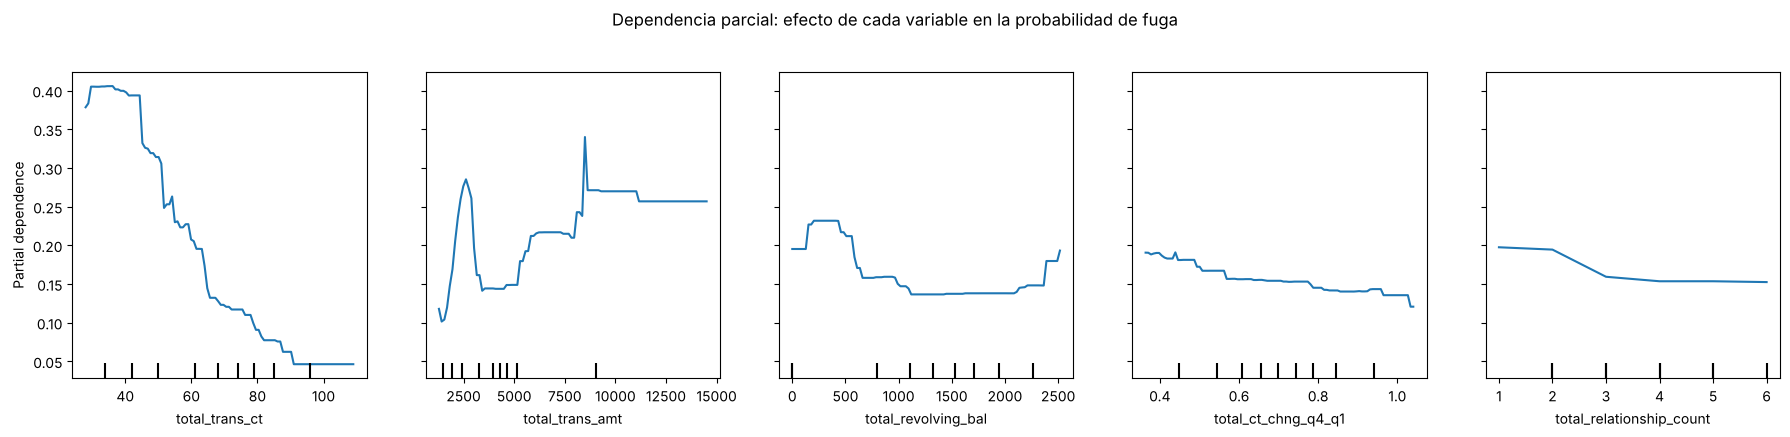

In [13]:
p = r_final["mejores_parametros"] or {}
modelo_interp = GradientBoostingClassifier(random_state=SEMILLA, **p).fit(X_train, y_train)
fig, ax = plt.subplots(figsize=(18, 4.2))
PartialDependenceDisplay.from_estimator(modelo_interp, X_train.sample(2000, random_state=SEMILLA).astype(float),
    ["total_trans_ct", "total_trans_amt", "total_revolving_bal", "total_ct_chng_q4_q1", "total_relationship_count"],
    response_method="predict_proba", method="brute", kind="average", ax=ax, n_cols=5)
plt.suptitle("Dependencia parcial: efecto de cada variable en la probabilidad de fuga", y=1.03)
plt.tight_layout(); plt.savefig(f"{FIGURAS_DIR}/dependencia_parcial.png", bbox_inches="tight"); plt.show()

* Pocas transacciones, saldo rotativo bajo, caída Q4→Q1 y pocos productos aumentan el riesgo.

## 7. Modelo final y lista priorizada
El modelo se reentrena con toda la base y se guarda. La lista usa predicciones fuera de muestra (`cross_val_predict`).

In [14]:
from sklearn.model_selection import cross_val_predict, StratifiedKFold
X_all = pd.concat([X_train, X_test]); y_all = pd.concat([y_train, y_test])
ids_all = pd.concat([datos["id_train"], datos["id_test"]])

# 1. Modelo final para producción
modelo_final = GradientBoostingClassifier(random_state=SEMILLA, **p).fit(X_all, y_all)
joblib.dump({"modelo": modelo_final, "columnas": X_all.columns.tolist(), "umbral": UMBRAL_FINAL},
            f"{MODELOS_DIR}/modelo_final_churn.joblib")
print("Modelo guardado en modelos/modelo_final_churn.joblib")

# 2. Probabilidad fuera de muestra para cada cliente de la base
prob_oof = cross_val_predict(GradientBoostingClassifier(random_state=SEMILLA, **p), X_all, y_all,
                             cv=StratifiedKFold(5, shuffle=True, random_state=SEMILLA), method="predict_proba", n_jobs=-1)[:, 1]
print("AUC fuera de muestra en toda la base: %.4f" % roc_auc_score(y_all, prob_oof))

Modelo guardado en modelos/modelo_final_churn.joblib


AUC fuera de muestra en toda la base: 0.9929


In [15]:
df_orig = datos["df_original"].set_index("clientnum")
lista = pd.DataFrame({"clientnum": ids_all.values, "prob_fuga": prob_oof})
lista = lista.join(df_orig[["total_trans_amt", "total_trans_ct", "total_ct_chng_q4_q1", "total_revolving_bal",
                            "total_relationship_count", "months_inactive_12_mon", "contacts_count_12_mon",
                            "card_category", "income_category", "churn"]], on="clientnum")
lista["segmento_riesgo"] = pd.cut(lista["prob_fuga"], bins=[-0.01, 0.2, UMBRAL_FINAL, 1.0], labels=["Bajo", "Medio", "Alto"])
lista["valor_en_riesgo"] = lista["prob_fuga"] * lista["total_trans_amt"]   # prob × valor transado anual
print("Distribución de segmentos en toda la base:\n", lista["segmento_riesgo"].value_counts(), "\n")

# Lista para el programa: SOLO clientes que siguen activos (churn = 0), ordenados por probabilidad
activos = (lista[lista["churn"] == 0].drop(columns="churn")
           .sort_values(["prob_fuga", "valor_en_riesgo"], ascending=False).reset_index(drop=True))
activos.insert(0, "prioridad", activos.index + 1)
activos.to_excel(f"{RESULTADOS_DIR}/lista_priorizada_clientes.xlsx", index=False)
print("Clientes activos por segmento:\n", activos["segmento_riesgo"].value_counts())
print("\nLista guardada en resultados/lista_priorizada_clientes.xlsx")
activos.head(10).round(3)

Distribución de segmentos en toda la base:
 segmento_riesgo
Bajo     8329
Alto     1611
Medio     187
Name: count, dtype: int64 



Clientes activos por segmento:
 segmento_riesgo
Bajo     8237
Alto      133
Medio     130
Name: count, dtype: int64

Lista guardada en resultados/lista_priorizada_clientes.xlsx


,prioridad,clientnum,prob_fuga,total_trans_amt,total_trans_ct,total_ct_chng_q4_q1,total_revolving_bal,total_relationship_count,months_inactive_12_mon,contacts_count_12_mon,card_category,income_category,segmento_riesgo,valor_en_riesgo
0,1,717561108,1.000,1629,32,0.778,549,4,3,2,Blue,$80K - $120K,Alto,1628.624
1,2,709465758,0.996,902,31,0.409,0,3,1,3,Blue,Less than $40K,Alto,898.841
2,3,710662158,0.995,2051,41,1.050,2517,1,3,3,Blue,$120K +,Alto,2041.632
3,4,720846558,0.995,2512,45,0.324,0,6,3,4,Blue,$80K - $120K,Alto,2499.383
4,5,719621958,0.990,1720,40,0.379,0,3,2,3,Blue,$60K - $80K,Alto,1703.652
5,6,788965683,0.990,2170,41,0.464,0,6,3,3,Blue,Less than $40K,Alto,2148.145
6,7,785432733,0.975,966,22,1.200,0,2,3,3,Gold,Less than $40K,Alto,941.819
7,8,716436483,0.975,2521,50,0.667,0,4,4,3,Blue,Less than $40K,Alto,2456.951
8,9,789175683,0.973,8352,71,0.821,2517,2,3,2,Silver,Less than $40K,Alto,8126.932
9,10,710096658,0.963,2191,42,0.500,1978,4,3,3,Blue,Less than $40K,Alto,2110.434


In [16]:
# Perfil de cada segmento de riesgo (toda la base): ¿cómo son los clientes en riesgo alto?
perfil = lista.groupby("segmento_riesgo", observed=True).agg(
    clientes=("clientnum", "size"), prob_media=("prob_fuga", "mean"), tasa_fuga_real=("churn", "mean"),
    trans_ct_mediana=("total_trans_ct", "median"), trans_amt_mediana=("total_trans_amt", "median"),
    cambio_ct_q4q1_mediana=("total_ct_chng_q4_q1", "median"), saldo_rotativo_mediana=("total_revolving_bal", "median"),
    productos_media=("total_relationship_count", "mean"), meses_inactivo_media=("months_inactive_12_mon", "mean"),
    contactos_media=("contacts_count_12_mon", "mean"))
perfil.round(2)

,clientes,prob_media,tasa_fuga_real,trans_ct_mediana,trans_amt_mediana,cambio_ct_q4q1_mediana,saldo_rotativo_mediana,productos_media,meses_inactivo_media,contactos_media
segmento_riesgo,,,,,,,,,,
Bajo,8329,0.01,0.01,71.0,4121.0,0.72,1372.0,3.92,2.27,2.35
Medio,187,0.29,0.30,48.0,2184.0,0.65,985.0,3.87,2.58,2.85
Alto,1611,0.90,0.92,43.0,2323.0,0.52,0.0,3.27,2.69,2.97


In [17]:
# Ejemplo de USO del modelo guardado con un cliente nuevo (así se implementaría en producción)
paquete = joblib.load(f"{MODELOS_DIR}/modelo_final_churn.joblib")
cliente_nuevo = X_test.iloc[[0]][paquete["columnas"]]
prob = paquete["modelo"].predict_proba(cliente_nuevo)[0, 1]
print(f"Probabilidad de fuga: {prob:.1%} -> {'OFRECER BENEFICIOS' if prob > paquete['umbral'] else 'monitorear'}")

Probabilidad de fuga: 0.3% -> monitorear


## Conclusiones
* Modelo elegido: Gradient Boosting (empatado en AUC con HistGB y Stacking, pero más simple e interpretable).
* La regresión logística (método del gradiente) es el modelo base: AUC ≈ 0,93.
* Con umbral 0,39 detecta ~93% de las fugas contactando ~17% de los clientes.
* Recomendaciones: alertas tempranas, atender contactos, venta cruzada y monitoreo trimestral.